### **PARTE 1 - CARGA Y EXPLORACIÓN DE DATOS**

##### Cargar del data set y dimensiones

In [96]:
# Instalar xlrd si no está instalado
!pip install xlrd -q

# Tratamiento de Datos
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import style

#Preprocesamiento y Modelo

from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNetCV

# Configurar estilo de gráficos
plt.style.use('ggplot')

# Preprocesado y análisis
from scipy import stats

# Configurar advertencias
import warnings
warnings.filterwarnings('ignore')

# Cargar archivo Excel .xls
df = pd.read_excel(r"C:\Users\dashi\OneDrive\Escritorio\Cursos\Machine Learning\concrete+compressive+strength\Concrete_Data.xls", sheet_name="Sheet1")
 

# Verificar carga
print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (1030, 9)



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


##### Tipos de variables

In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

### Verificar valores faltantes y valores duplicados

In [98]:
# Valores faltantes por variable

faltantes = df.isnull().sum()

print(faltantes)
print("\nTotal de valores faltantes:", faltantes.sum())

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

Total de valores faltantes: 0


In [99]:
duplicados_totales = df.duplicated().sum()
print(f"Filas completamente duplicadas: {duplicados_totales}")

Filas completamente duplicadas: 25


##### Obtener estadísticas descriptivas de las variables numéricas

In [100]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


##### Conclusiones de la Estadística Descriptiva

1. La `Resistencia a compresión del concreto` del concreto varía entre 2.33 MPa y 82.60 MPa.
2. La `Resistencia promedio` es de aproximadamente 35.82 MPa.
3. El `cemento` tiene una media de 281.17 kg/m3, con valores entre 102.00 y 540.00 kg/m3.
4. La `cantidad de agua` tiene una media de 181.57 kg/m3.
5. La `edad de curado` presenta una variabilidad considerable: va desde 1 día hasta 365 días, con una mediana de 28 días. 
6. Algunas variables, como escoria de alto horno, ceniza volante y superplastificante, presentan valores mínimos de cero. Esto indica que estos componentes no están presentes en todas las mezclas; no representa un dato faltante. 

#### Identificación de variables dependiente e independientes

Con el fin de facilitar el desarrollo posterior del notebook, se considera conveniente renombrar las columnas con nombres más cortos y claros

In [101]:
df.columns = [
    "cemento",
    "escoria_alto_horno",
    "ceniza_volante",
    "agua",
    "superplastificante",
    "agregado_grueso",
    "agregado_fino",
    "edad_dias",
    "resistencia_comprension"
]

df.head()

,cemento,escoria_alto_horno,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_comprension
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


##### Respuesta a la pregunta de análisis

¿Qué información contiene el dataset y qué queremos predecir?

El dataset contiene información histórica de 1,030 mezclas de concreto. Cada registro describe la composición de una mezcla mediante las cantidades de cemento, escoria de alto horno, ceniza volante, agua, superplastificante, agregado grueso y agregado fino, además de la edad de curado en días. 


In [102]:
y = df["resistencia_comprension"]



In [103]:
x = df.drop(columns=["resistencia_comprension"])

### Análisis de Normalidad de las variables

##### Histogramas

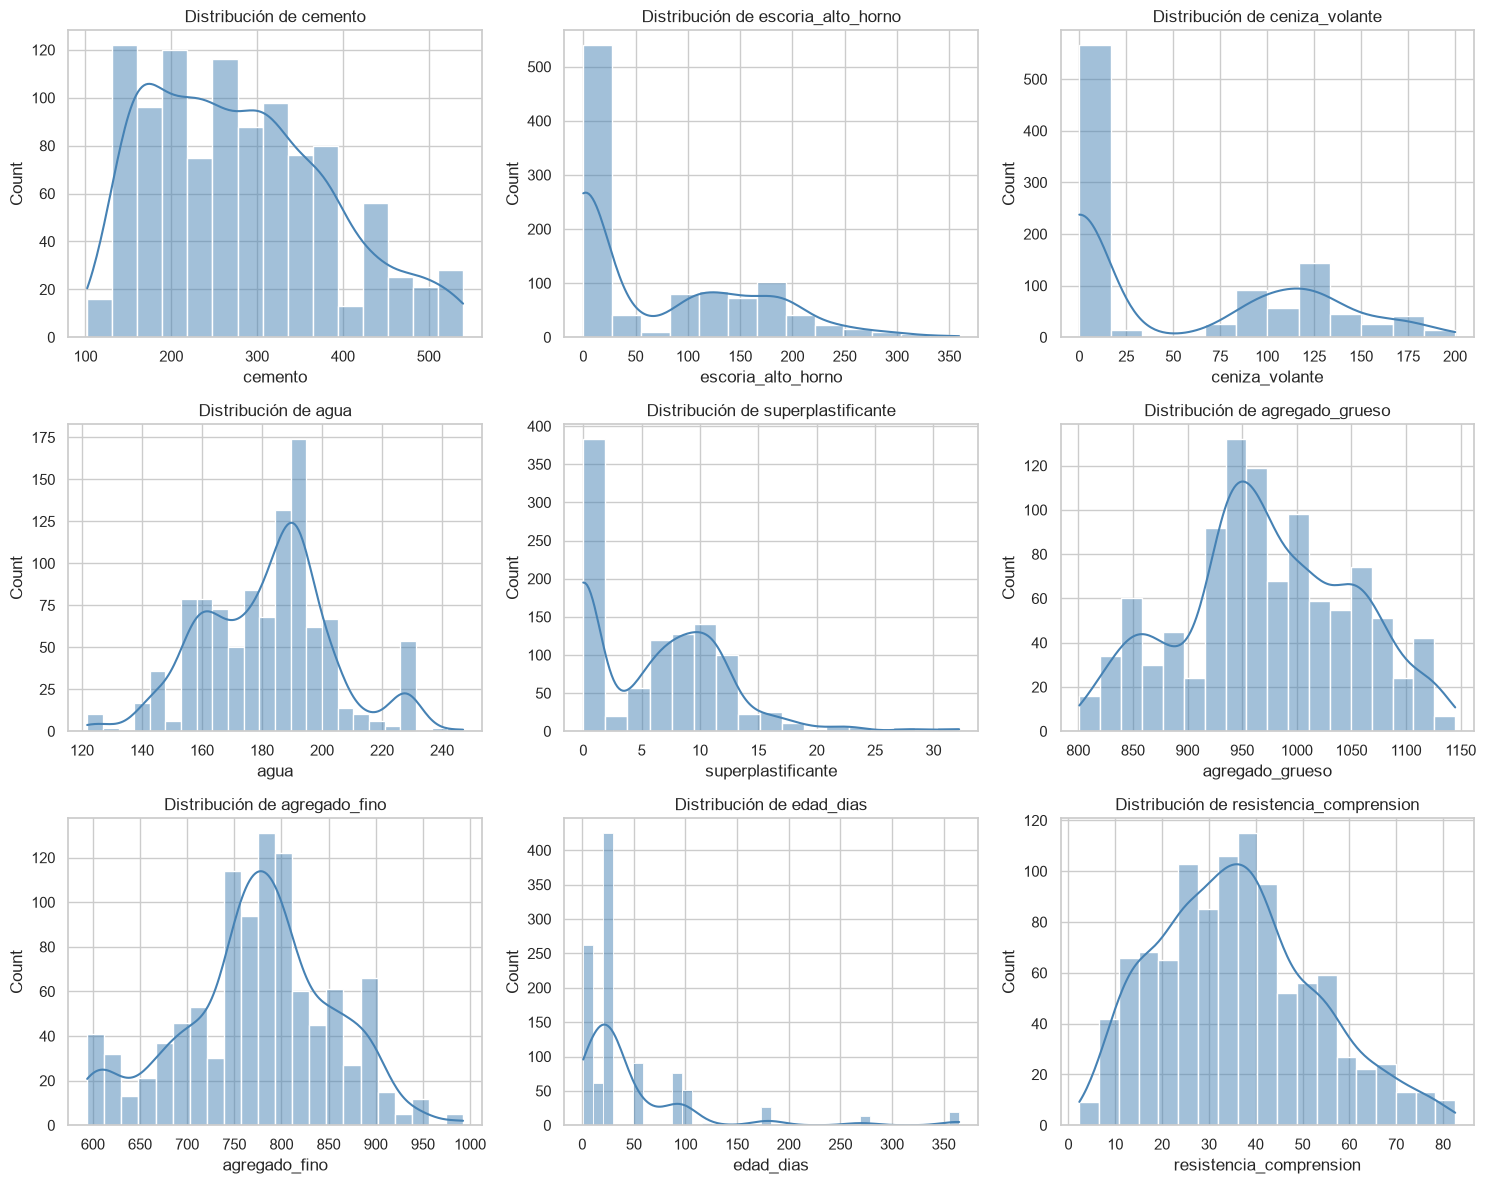

In [104]:
sns.set_theme(style="whitegrid") 

fig, axes = plt.subplots(3, 3, figsize=(15,12)) 

for ax, variable in zip(axes.flat, df.columns): 

    sns.histplot( 
        data=df, 
        x=variable, 
        kde=True, 
        color="steelblue", 
        ax=ax 
    ) 
    ax.set_title(f'Distribución de {variable}') 
plt.tight_layout() 
plt.show()

##### Asimetría y curtosis

In [105]:
forma_distribuciones = pd.DataFrame({
    "Asimetría": df.skew(),
    "Curtosis": df.kurtosis()
})

forma_distribuciones.round(3)

,Asimetría,Curtosis
cemento,0.510,-0.521
escoria_alto_horno,0.801,-0.508
ceniza_volante,0.537,-1.329
agua,0.074,0.123
superplastificante,0.908,1.413
agregado_grueso,-0.040,-0.599
agregado_fino,-0.253,-0.102
edad_dias,3.269,12.169
resistencia_comprension,0.417,-0.314


##### Pruebas de Normalidad

In [106]:
for variable in df.columns:
    datos = df[variable]

    #Shapiro
    stat_sw,p_sw = stats.shapiro(datos)

    #D'Agostino
    stat_d, p_d= stats.normaltest(datos)

    #Anderson-Darling
    ad = stats.anderson(datos)

    print(variable)
    print("Shapiro p:", p_sw)
    if p_sw > 0.05:
        print("Interpretación: No hay evidencia suficiente para rechazar H0. Los datos pueden ser normales.")
    else:
        print("Interpretación: Rechazamos H0. Los datos NO son normales.")
                 
    print("D'Agostino p:", p_d)
    if p_d > 0.05:
            print("Interpretación: No hay evidencia suficiente para rechazar H0. Los datos pueden ser normales.")
    else:
            print("Interpretación: Rechazamos H0. Los datos NO son normales.")
    print("Anderson-Darling p:", ad.statistic)
    print("-"*40)

         

cemento
Shapiro p: 2.0765235729118928e-16
Interpretación: Rechazamos H0. Los datos NO son normales.
D'Agostino p: 3.869634310956988e-14
Interpretación: Rechazamos H0. Los datos NO son normales.
Anderson-Darling p: 10.398819262112283
----------------------------------------
escoria_alto_horno
Shapiro p: 5.7969462570532356e-33
Interpretación: Rechazamos H0. Los datos NO son normales.
D'Agostino p: 4.314604754494087e-24
Interpretación: Rechazamos H0. Los datos NO son normales.
Anderson-Darling p: 79.41450940005234
----------------------------------------
ceniza_volante
Shapiro p: 4.140027498524051e-36
Interpretación: Rechazamos H0. Los datos NO son normales.
D'Agostino p: 0.0
Interpretación: Rechazamos H0. Los datos NO son normales.
Anderson-Darling p: 114.32440792916668
----------------------------------------
agua
Shapiro p: 1.4733856014643884e-10
Interpretación: Rechazamos H0. Los datos NO son normales.
D'Agostino p: 0.4353473831543476
Interpretación: No hay evidencia suficiente para r

##### Conclusiones del análisis de normalidad

1. Con un nivel de significancia de α= 0.05, todas las variables presentan un p-valor menor que 0.05 en la prueba de Shapiro-Wilk. Por tanto, se rechaza la hipótesis de normalidad para todas las variables del dataset.
2. La variable con mayor desviación de la normalidad es edad_dias, con una asimetría positiva de aproximadamente 3.26 y una curtosis de aproximadamente 12.10. Esto indica una distribución con cola derecha pronunciada y valores extremos altos.
3. Las variables escoria_alto_horno, ceniza_volante y superplastificante no se distribuyen normalmente porque muchas mezclas tienen valor cero en esos componentes. Esto es coherente con la formulación del concreto: no todas las mezclas incorporan materiales suplementarios o aditivos.
4. Aunque agua, agregado_grueso, agregado_fino y resistencia_compresion_mpa tienen distribuciones visualmente más cercanas a la normalidad, la prueba de Shapiro-Wilk detecta diferencias estadísticamente significativas debido al tamaño muestral de 1,030 observaciones.
La falta de normalidad en las variables originales no impide entrenar modelos de regresión lineal. Para validar correctamente el supuesto de normalidad del modelo, se deberá analizar la distribución de los residuos después de entrenar cada modelo de regresión.

##### Detección univariante de outliers (Método IQR)

In [107]:
variables = [
    'cemento',
    'escoria_alto_horno',
    'ceniza_volante',
    'agua',
    'superplastificante',
    'agregado_grueso',
    'agregado_fino',
    'edad_dias',
    'resistencia_comprension',
]

resultado_iqr = []

for col in variables:

    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    mediana = df[col].median()

    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr

    n_outliers = ((df[col] < li) | (df[col] > ls)).sum()

    resultado_iqr.append([
        col,
        round(q1,2),
        round(q3,2),
        round(mediana,2),
        round(iqr,2),
        round(li,2),
        round(ls,2),
        n_outliers,
        round(n_outliers/len(df)*100,2)
    ])

tabla_iqr = pd.DataFrame(
    resultado_iqr,
    columns=[
        'Variable',
        'Q1',
        'Q3',
        'Mediana',
        'IQR',
        'Limite Inferior',
        'Limite Superior',
        'Outliers',
        '% Outliers'
    ]
)

tabla_iqr

,Variable,Q1,Q3,Mediana,IQR,Limite Inferior,Limite Superior,Outliers,% Outliers
0,cemento,192.38,350.00,272.90,157.62,-44.06,586.44,0,0.00
1,escoria_alto_horno,0.00,142.95,22.00,142.95,-214.42,357.38,2,0.19
2,ceniza_volante,0.00,118.27,0.00,118.27,-177.40,295.68,0,0.00
3,agua,164.90,192.00,185.00,27.10,124.25,232.65,9,0.87
4,superplastificante,0.00,10.16,6.35,10.16,-15.24,25.40,10,0.97
5,agregado_grueso,932.00,1029.40,968.00,97.40,785.90,1175.50,0,0.00
6,agregado_fino,730.95,824.00,779.51,93.05,591.38,963.58,5,0.49
7,edad_dias,7.00,56.00,28.00,49.00,-66.50,129.50,59,5.73
8,resistencia_comprension,23.71,46.14,34.44,22.43,-9.94,79.78,4,0.39


Mediante el método del rango intercuartílico, con un factor de 1,5, se identificaron 89 registros con al menos un valor potencialmente atípico, equivalentes al 8,64 % del dataset. La edad de curado presentó la mayor cantidad de observaciones señaladas, con 59 registros correspondientes a edades de 180, 270, 360 y 365 días. También se detectaron valores extremos en escoria de alto horno, agua, superplastificante, agregado fino y resistencia a compresión. Estos resultados describen valores inusuales respecto a la distribución de cada variable, pero no demuestran errores de registro. Por ello, se conservará el dataset original.

### **PARTE 2 - ANÁLISIS DE RELACIONES ENTRE VARIABLES**
##### Construcción de matriz de correlación

In [108]:
# Seleccionar las columnas numéricas 
datos_numericos = df.select_dtypes(include=[np.number])

#calcular la matriz de correlación
corr_matrix = datos_numericos.corr(method='pearson')

#Mostrar la matriz
display(corr_matrix.round(4))

,cemento,escoria_alto_horno,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_comprension
cemento,1.0000,-0.2752,-0.3975,-0.0815,0.0928,-0.1094,-0.2227,0.0819,0.4978
escoria_alto_horno,-0.2752,1.0000,-0.3236,0.1073,0.0434,-0.2840,-0.2816,-0.0442,0.1348
ceniza_volante,-0.3975,-0.3236,1.0000,-0.2570,0.3773,-0.0100,0.0791,-0.1544,-0.1058
agua,-0.0815,0.1073,-0.2570,1.0000,-0.6575,-0.1823,-0.4506,0.2776,-0.2896
superplastificante,0.0928,0.0434,0.3773,-0.6575,1.0000,-0.2663,0.2225,-0.1927,0.3661
agregado_grueso,-0.1094,-0.2840,-0.0100,-0.1823,-0.2663,1.0000,-0.1785,-0.0030,-0.1649
agregado_fino,-0.2227,-0.2816,0.0791,-0.4506,0.2225,-0.1785,1.0000,-0.1561,-0.1672
edad_dias,0.0819,-0.0442,-0.1544,0.2776,-0.1927,-0.0030,-0.1561,1.0000,0.3289
resistencia_comprension,0.4978,0.1348,-0.1058,-0.2896,0.3661,-0.1649,-0.1672,0.3289,1.0000


##### Representación gráfica de las correlaciones

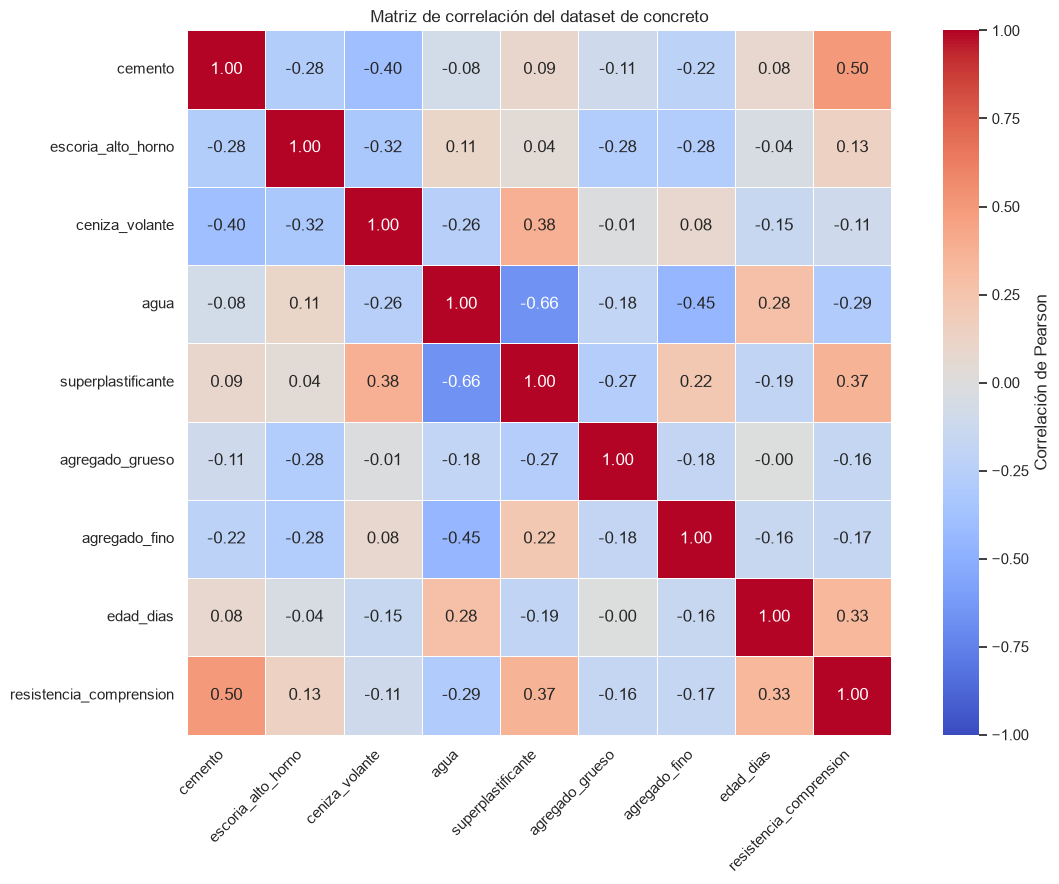

In [109]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title("Matriz de correlación del dataset de concreto")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Variables con mayor correlación positiva y negativa con la resistencia

In [110]:
correlaciones_resistencia = corr_matrix["resistencia_comprension"].drop("resistencia_comprension").sort_values(ascending=False)

print(correlaciones_resistencia)

cemento               0.497833
superplastificante    0.366102
edad_dias             0.328877
escoria_alto_horno    0.134824
ceniza_volante       -0.105753
agregado_grueso      -0.164928
agregado_fino        -0.167249
agua                 -0.289613
Name: resistencia_comprension, dtype: float64


#### Interpretacion
Los resultados muestran que:
1. Cemento (r = 0.498) es la variable más relacionada con la resistencia. En general. cuando aumenta el cemento, la resistencia también tiende a aumentar. 
2. Superplastificante (r = 0.366) permite reducir el agua necesaria sin afectar la trabajabilidad de la mezcla, favoreciendo la resistencia.
3. Edad (r = 0.329) presentan relaciones positivas moderadas.A medida que avanza el proceso de curado, el concreto desarrolla una mayor resistencia mecánica.
3. Agua (r = -0.290) muestra la relación negativa más importante. Un exceso de agua puede generar una estructura más porosa y, en consecuencia, reducir la resistencia final del concreto. 

Conclusión
La resistencia del concreto parece depender principalmente de la cantidad de cemento, del uso de superplastificante y del tiempo de curado. 


#### Identificación de variables independientes altamente correlacionadas.

In [111]:
# Excluir la variable dependiente para comparar solo las variables independientes
variable_dependiente = "resistencia_comprension"
predictores = df.columns.drop(variable_dependiente)
corr_predictores = df.loc[:, predictores].corr(method="pearson")

# Umbral para considerar una correlación alta
umbral = 0.70

# Conservar solo un triángulo de la matriz para no duplicar pares
mascara_superior = np.triu(np.ones(corr_predictores.shape, dtype=bool), k=1)
pairs = (
    corr_predictores.where(mascara_superior)
    .stack()
    .rename("pearson_r")
    .reset_index()
)
pairs.columns = ["variable_1", "variable_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False)

correlaciones_altas = pairs[pairs["abs_r"] >= umbral]
if correlaciones_altas.empty:
    print(f"No se encontraron pares con |r| >= {umbral:.2f}.")
    print("Pares con mayor correlación absoluta:")
    display(pairs.head(5).reset_index(drop=True).round(3))
else:
    print(f"Pares de variables independientes con |r| >= {umbral:.2f}:")
    display(correlaciones_altas.reset_index(drop=True).round(3))


No se encontraron pares con |r| >= 0.70.
Pares con mayor correlación absoluta:


,variable_1,variable_2,pearson_r,abs_r
0,agua,superplastificante,-0.657,0.657
1,agua,agregado_fino,-0.451,0.451
2,cemento,ceniza_volante,-0.397,0.397
3,ceniza_volante,superplastificante,0.377,0.377
4,escoria_alto_horno,ceniza_volante,-0.324,0.324


### **PARTE 3 - CONSTRUCCIÓN DE MODELOS**
##### Dividir los datos

In [116]:
# Division de los datos
#20% EN EL TEST 
#80% EN EL TRAIN 

X = df.drop(columns = 'resistencia_comprension')
y = df['resistencia_comprension']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y.values.reshape(-1,1),
    test_size = 0.2,
    random_state = 42,
    shuffle = True)

##### Crear y entrenar el modelo de Mínimos Cuadrados (OLS)

In [120]:
ols_modelo = LinearRegression()
ols_modelo.fit(X = X_train, y = y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 8)","[[0.12,0.11,0.08,...,0.02,0.02,0.12]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['cemento','escoria_alto_horno','ceniza_volante',...,'agregado_grueso', 'agregado_fino','edad_dias']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-28.64]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


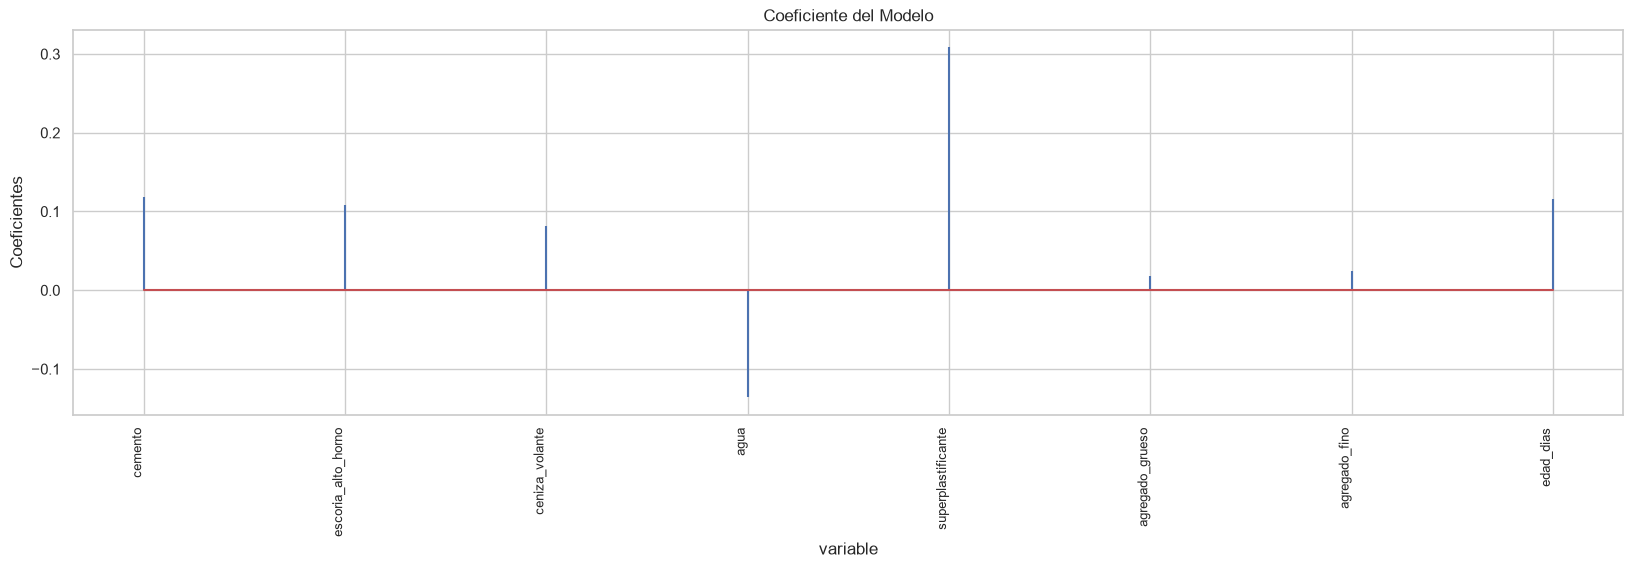

In [121]:
# Coeficientes del modelo

df_coeficientes = pd.DataFrame(
    {'predictor':X_train.columns,
     'coef': modelo.coef_.flatten()})

fig, ax = plt.subplots(figsize =(20,5))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation = 90, ha = 'right', size = 9)
ax.set_ylabel('Coeficientes')
ax.set_xlabel('variable')
ax.set_title('Coeficiente del Modelo')
plt.show()

In [122]:
# Predicciones del test

predicciones = modelo.predict(X= X_test)
predicciones = predicciones.flatten()
predicciones[:10]

array([59.65716303, 52.03714377, 63.51983933, 51.57136586, 17.22016023,
       39.86885347, 26.7014459 , 44.72001905, 29.35815964, 38.19395083])

In [123]:
from sklearn.metrics import r2_score

r2_ols = r2_score(
    y_true  = y_test,
    y_pred = predicciones)

print(f'El coeficiente determinacion del test es: {r2_ols}')

El coeficiente determinacion del test es: 0.6275416055429021


##### Crear y entrenar el modelo Regresión Ridge

In [124]:
modelo_ridge = Ridge(alpha = 1.0)
modelo_ridge.fit(X=X_train, y = y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 